# Example 05: Slope displacement models

The slope-displacement models estimate the permanent displacement of a sliding mass from its yield coefficient $k_y$ and ground-motion parameters. The ground-motion parameters come from a ground-motion model, so the same scenario supplies each model with the quantities it needs: PGA for Rathje and Saygili (2008), the spectral acceleration at 1.5 times the period of the mass for Bray and Travasarou (2007), and PGA with $S_a$(1 s) for Watson-Lamprey and Abrahamson (2006). Displacements are in cm.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pygmm
from pygmm import slope_displacement

%matplotlib inline

PGA = 0.111 g, PGV = 8.1 cm/s, Sa(1.5 Ts) = 0.156 g, Sa(1 s) = 0.067 g


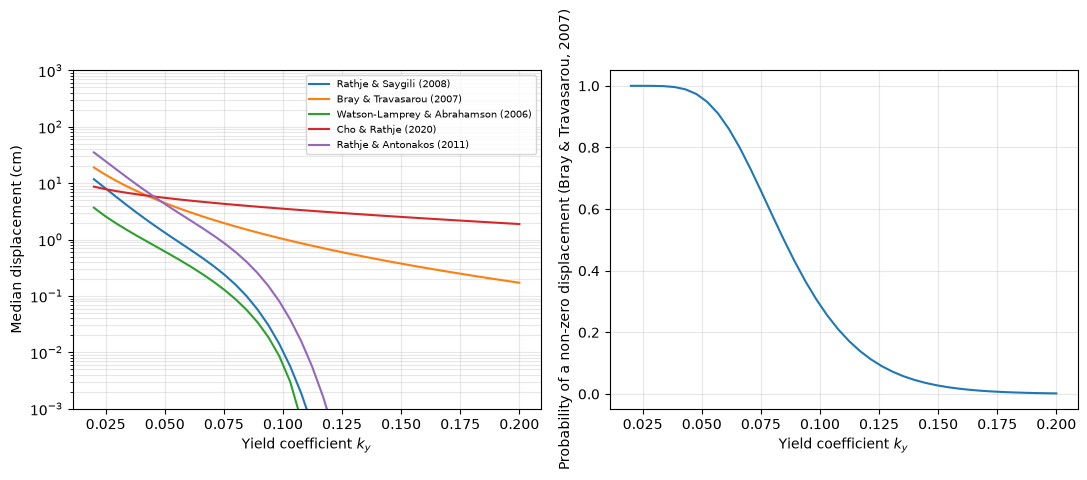

In [2]:
scenario = pygmm.Scenario(
    mag=6.5,
    dist_rup=20.0,
    dist_jb=20.0,
    dist_x=20.0,
    dip=90.0,
    mechanism="SS",
    v_s30=760.0,
)

gmm = pygmm.ChiouYoungs2014(scenario)
pga = gmm.pga
pgv = gmm.pgv
period_slide = 0.3  # s
psa_dts = gmm.interp_spec_accels([1.5 * period_slide])[0]
psa_1s = gmm.interp_spec_accels([1.0])[0]
print(
    f"PGA = {pga:.3f} g, PGV = {pgv:.1f} cm/s, "
    f"Sa(1.5 Ts) = {psa_dts:.3f} g, Sa(1 s) = {psa_1s:.3f} g"
)

yield_coefs = np.linspace(0.02, 0.2, 40)
disps = {
    "Rathje & Saygili (2008)": slope_displacement.calc_disp_rs08(
        yield_coefs, pga, mag=6.5
    ),
    "Bray & Travasarou (2007)": slope_displacement.calc_disp_bt07(
        yield_coefs, period_slide, psa_dts, mag=6.5
    ),
    "Watson-Lamprey & Abrahamson (2006)": slope_displacement.calc_disp_wla06(
        yield_coefs, pga, psa_1s, mag=6.5
    ),
    "Cho & Rathje (2020)": slope_displacement.calc_disp_cr20(
        yield_coefs, period_slide, pga=pga, mag=6.5
    ),
    "Rathje & Antonakos (2011)": slope_displacement.calc_disp_ra11(
        yield_coefs, pga, period_slide, 0.6, mag=6.5
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, d in disps.items():
    axes[0].plot(yield_coefs, d, label=name)
axes[0].set(
    xlabel="Yield coefficient $k_y$",
    ylabel="Median displacement (cm)",
    yscale="log",
    ylim=(1e-3, 1e3),
)
axes[1].plot(
    yield_coefs,
    slope_displacement.calc_prob_disp_bt07(yield_coefs, period_slide, psa_dts),
)
axes[1].set(
    xlabel="Yield coefficient $k_y$",
    ylabel="Probability of a non-zero displacement (Bray & Travasarou, 2007)",
)
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=7)
fig.tight_layout()

## Dependence on the ground motion

The displacement of a slope with $k_y$ = 0.1 and $T_s$ = 0.3 s for magnitudes of 5.5 to 7.5 and distances of 5 to 100 km, with the Bray and Travasarou (2007) and Rathje and Saygili (2008) models.

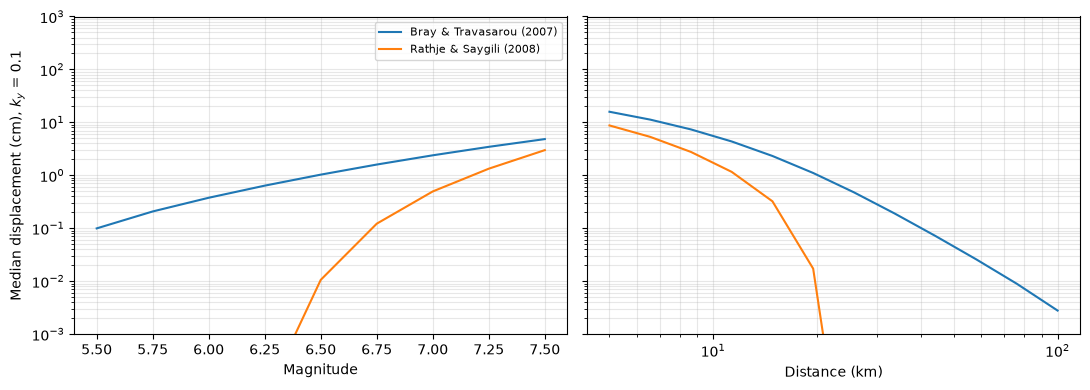

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, key, values, label in [
    (axes[0], "mag", np.linspace(5.5, 7.5, 9), "Magnitude"),
    (axes[1], "dist", np.geomspace(5.0, 100.0, 12), "Distance (km)"),
]:
    bt, rs = [], []
    for v in values:
        s = (
            scenario.copy_with(mag=v)
            if key == "mag"
            else scenario.copy_with(dist_rup=v, dist_jb=v, dist_x=v)
        )
        m = pygmm.ChiouYoungs2014(s)
        mag = s["mag"]
        bt.append(
            slope_displacement.calc_disp_bt07(
                0.1, 0.3, m.interp_spec_accels([0.45])[0], mag=mag
            )
        )
        rs.append(slope_displacement.calc_disp_rs08(0.1, m.pga, mag=mag))
    ax.plot(values, bt, label="Bray & Travasarou (2007)")
    ax.plot(values, rs, label="Rathje & Saygili (2008)")
    ax.set(xlabel=label, yscale="log", ylim=(1e-3, 1e3))
    if key == "dist":
        ax.set_xscale("log")
    ax.grid(True, which="both", alpha=0.3)
axes[0].set_ylabel("Median displacement (cm), $k_y$ = 0.1")
axes[0].legend(fontsize=8)
fig.tight_layout()

### Observations

- **The models disagree by more than an order of magnitude at larger yield coefficients.** For $k_y$ = 0.02 the median displacements are 4 to 35 cm; for $k_y$ = 0.1, close to the PGA of 0.11 g, Bray and Travasarou (2007) gives 1.0 cm and Cho and Rathje (2020) 3.5 cm, but Rathje and Saygili (2008), Rathje and Antonakos (2011) and Watson-Lamprey and Abrahamson (2006) give 0.006 to 0.06 cm, because their median displacement falls quickly once the yield coefficient approaches the PGA.
- **The probability of a non-zero displacement** (Bray and Travasarou, 2007) is near 1 below $k_y$ = 0.04, 0.5 at about 0.08 and 0.1 at 0.125.
- **Magnitude and distance**: for $k_y$ = 0.1 the Bray and Travasarou (2007) displacement changes by a factor of 50 from $M_w$ 5.5 to 7.5 and by a factor of 6000 from 5 to 100 km; Rathje and Saygili (2008) is much more sensitive and is negligible beyond about 20 km and below $M_w$ 6.5.